# Regresión lineal con descenso de gradiente

Se ajusta una recta sobre datos reales del dataset California Housing para
estimar el valor de una vivienda a partir del ingreso medio de la zona.

Crespo Hernández Kitzia Marisol. No. de Control: C23171148

## 1. Carga de datos

California Housing viene incluido en scikit-learn y describe zonas censales de
California. De las más de veinte mil zonas se toman las primeras cincuenta, para
trabajar con un conjunto manejable y poder ver los puntos en la gráfica.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing

# Configuramos el estilo de las gráficas para que se vean profesionales en clase
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# 1. CARGA DE DATOS (Ejemplo: California Housing)
california = fetch_california_housing(as_frame=True)

# Tomamos por ejemplo el ingreso medio (MedInc) vs el valor de la casa (MedHouseVal)
# El ingreso viene en decenas de miles de dólares y el valor de la casa en cientos
# de miles, de modo que un ingreso de 5.0 equivale a 50,000 dólares.
X = california.data['MedInc'].values[:50] # Tomamos un subconjunto pequeño para simplificar el ejemplo
Y = california.target.values[:50]

print(f"Datos cargados con éxito: {len(X)} zonas analizadas.")

Datos cargados con éxito: 50 zonas analizadas.


## 2. Inicialización de parámetros

El modelo es una recta `Y = w * X + b`. Los dos parámetros arrancan en cero y el
descenso de gradiente se encarga de irlos acercando a su valor correcto.

In [2]:
# 2. INICIALIZACIÓN DE PARÁMETROS
# w es la pendiente, cuánto sube el valor de la vivienda por cada unidad de ingreso.
w = 0.0
# b es la ordenada al origen, lo que predice el modelo cuando el ingreso vale cero.
b = 0.0

# Hiperparámetros
learning_rate = 0.005 # Tasa de aprendizaje ajustada para esta escala
epochs = 1500         # Iteraciones de entrenamiento
n = len(X)

# Historial para graficar la evolución del costo si lo deseas mostrar
historial_costos = []

## 3. Entrenamiento

Cada época repite tres pasos. Predecir con los parámetros actuales, medir qué tan
lejos quedó la predicción, y corregir los parámetros en la dirección que reduce ese
error.

In [3]:
# 3. ENTRENAMIENTO
for epoch in range(epochs):
    # Predicción actual
    Y_pred = w * X + b                      # X -> Features   Y -> Labels

    # Cálculo del Costo (MSE)
    cost = (1 / (2 * n)) * np.sum((Y_pred - Y) ** 2)
    historial_costos.append(cost)

    # Derivadas parciales (Gradientes)
    dw = (2 / n) * np.sum((Y_pred - Y) * X)
    db = (2 / n) * np.sum(Y_pred - Y)

    # Actualización de pesos
    # Cada parámetro se mueve en sentido contrario a su gradiente, con pasos
    # del tamaño de learning_rate.
    w = w - learning_rate * dw
    b = b - learning_rate * db

print("¡Entrenamiento completado!")
print(f"Ecuación final aprendida: Valor de la vivienda = {w:.4f} * (Ingreso medio) + {b:.4f}")

¡Entrenamiento completado!
Ecuación final aprendida: Valor de la vivienda = 0.4449 * (Ingreso medio) + 0.5895


## 4. Visualización de resultados

Los puntos azules son las zonas reales y la línea roja es la recta que aprendió el
modelo.

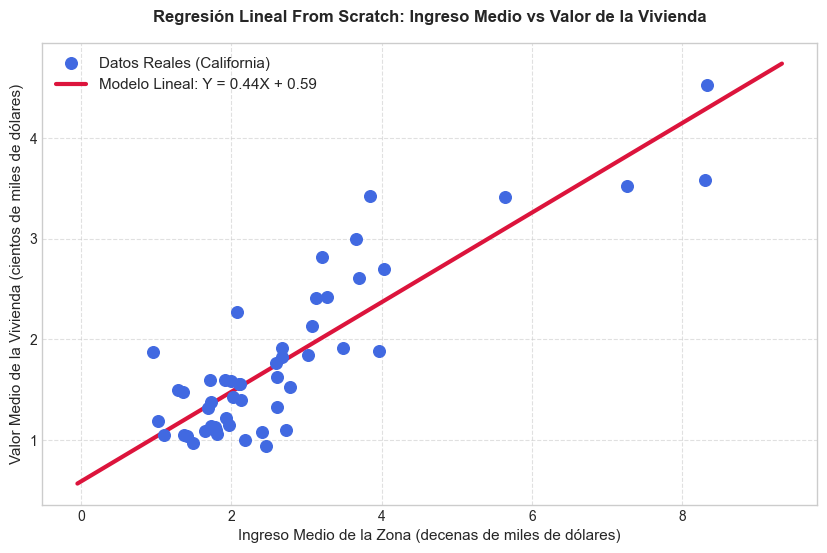

In [4]:
# 4. VISUALIZACIÓN DE RESULTADOS
plt.figure(figsize=(10, 6))

# Dibujar los puntos reales (Zonas de California)
plt.scatter(X, Y, color='royalblue', s=70, label='Datos Reales (California)', zorder=5)

# Dibujar la línea de tendencia aprendida por el modelo
X_linea = np.linspace(min(X) - 1, max(X) + 1, 100)
Y_linea = w * X_linea + b
plt.plot(X_linea, Y_linea, color='crimson', linewidth=3, label=f'Modelo Lineal: Y = {w:.2f}X + {b:.2f}')

# Etiquetas y formato estético
plt.title('Regresión Lineal From Scratch: Ingreso Medio vs Valor de la Vivienda', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Ingreso Medio de la Zona (decenas de miles de dólares)', fontsize=11)
plt.ylabel('Valor Medio de la Vivienda (cientos de miles de dólares)', fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

## 5. Evolución del costo

Si la curva baja y se aplana, el modelo terminó de aprender. Si siguiera bajando al
llegar a la última época, faltarían iteraciones.

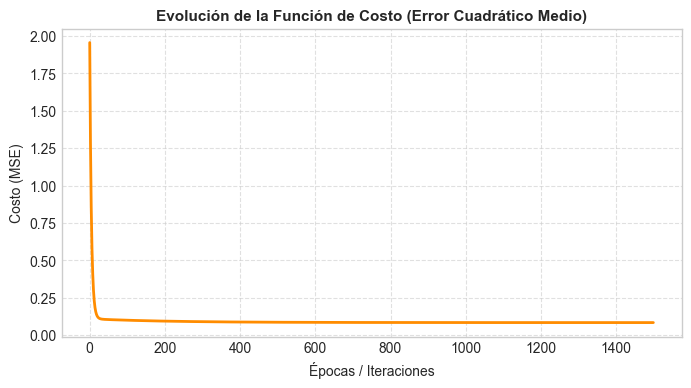

In [5]:
# 5. EVOLUCIÓN DE LA FUNCIÓN DE COSTO
plt.figure(figsize=(8, 4))
plt.plot(range(epochs), historial_costos, color='darkorange', linewidth=2)
plt.title('Evolución de la Función de Costo (Error Cuadrático Medio)', fontsize=11, fontweight='bold')
plt.xlabel('Épocas / Iteraciones', fontsize=10)
plt.ylabel('Costo (MSE)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## Interpretación de los resultados

La recta aprendida es **Valor = 0.4449 · Ingreso + 0.5895**.

El ingreso está en decenas de miles de dólares y el valor de la vivienda en cientos
de miles, así que la pendiente se lee de esta forma. Por cada 10,000 dólares más de
ingreso medio en la zona, el modelo estima alrededor de 44,500 dólares más en el
valor de la vivienda.

La ordenada al origen, 0.5895, representaría el valor estimado de una vivienda en una zona
con ingreso medio igual a cero. Sin embargo, como el ingreso mínimo observado es 0.95, un
ingreso de cero queda fuera del rango analizado y no tiene una interpretación práctica.

La curva del costo cae de 1.96 a 0.10 en las primeras cincuenta épocas y de ahí se aplana, señal
de que 1500 épocas bastaron para este conjunto.

La tendencia muestra que las zonas con mayores ingresos suelen tener viviendas más caras,
aunque los datos presentan cierta dispersión, ya que el ingreso por sí solo no explica
completamente todo el valor de una vivienda.